# <span style="color:green"> Numerical Simulation Laboratory </span>
## <span style="color:brown"> Python Exercise 11 </span>
## <span style="color:orange"> Keras - Neural Network regression </span>

### Overview 

In this notebook our task will be to perform machine learning regression on noisy data with a Neural Network (NN).

We will explore how the ability to fit depends on the structure of the NN. The goal is also to build intuition about why prediction is difficult.

### The Prediction Problem

Consider a probabilistic process that gives rise to labeled data $(x,y)$. The data is generated by drawing samples from the equation

$$
    y_i= f(x_i) + \eta_i,
$$

where $f(x_i)$ is some fixed, but (possibly unknown) function, and $\eta_i$ is a Gaussian, uncorrelate noise variable such that

$$
\langle \eta_i \rangle=0 \\
\langle \eta_i \eta_j \rangle = \delta_{ij} \sigma
$$

We will refer to the $f(x_i)$ as the **true features** used to generate the data. 

To make predictions, we will consider a NN that depends on its parameters, weights and biases. The functions that the NN can model respresent the **model class** that we are using to try to model the data and make predictions.

To learn the parameters of the NN, we will train our models on a **training data set** and then test the effectiveness of the NN on a *different* dataset, the **validation data set**. The reason we must divide our data into a training and test dataset is that the point of machine learning is to make accurate predictions about new data we have not seen.

To measure our ability to predict, we will learn our parameters by fitting our training dataset and then making predictions on our test data set. One common measure of predictive  performance of our algorithm is to compare the predictions,$\{y_j^\mathrm{pred}\}$, to the true values $\{y_j\}$. A commonly employed measure for this is the sum of the mean square-error (MSE) on the test set:
$$
MSE= \frac{1}{N_\mathrm{test}}\sum_{j=1}^{N_\mathrm{test}} (y_j^\mathrm{pred}-y_j)^2
$$

We will try to get a qualitative picture by examining plots on validation and training data.

### Linear fit

We start by considering the very simple case:
$$
f(x)=2x+1
$$

Let's start defining the parameters of an ideal linear function which we are going to predict through a neural network regression

In [2]:
# target parameters of f(x) = m*x + b
m = 2 # slope
b = 1 # intersect

Now let's generate a set of input data which will slightly deviate from our ideal behaviour using a random noise (that actually is set to zero):

In [3]:
import numpy as np

# generate training inputs
np.random.seed(0)
x_train = np.random.uniform(-1, 1, 500)
x_valid = np.random.uniform(-1, 1, 50)
x_valid.sort()
y_target = m * x_valid + b # ideal (target) linear function

sigma = 0.2 # noise standard deviation, for the moment it is absent
y_train = np.random.normal(m * x_train + b, sigma) # actual measures from which we want to guess regression parameters
y_valid = np.random.normal(m * x_valid + b, sigma)

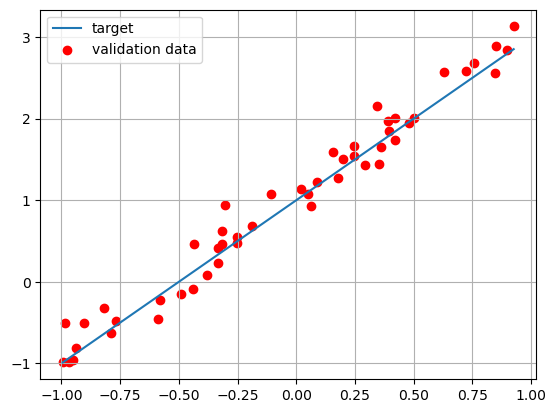

In [4]:
# plot validation and target dataset
import matplotlib.pyplot as plt
plt.plot(x_valid, y_target, label='target')
plt.scatter(x_valid, y_valid, color='r', label='validation data')
plt.legend()
plt.grid(True)
plt.show()

If you remember how a single node of a neural network works, you can easily spot that **just a single neuron can make the job**. So let's start using a simple Sequential model with just one layer on one neuron only!

In [5]:
# compose the NN model
import tensorflow as tf
from tensorflow import keras

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras import backend as K
from tensorflow.keras.utils import get_custom_objects

model = tf.keras.Sequential()
model.add(Input(shape=(1,)))
model.add(Dense(1))

# compile the model choosing optimizer, loss and metrics objects
model.compile(optimizer='sgd', loss='mse', metrics=['mse'])

In [6]:
# get a summary of our composed model
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

We are now going to train our model, that is we feed the neuron with the set of training pair x, y_train from which the optimizer will find the best weights to minimize the Mean Square Error loss function (out linear regression function).

In [7]:
# fit the model using training dataset
# over 10 epochs of 32 batch size each
# report training progress against validation data
history = model.fit(x=x_train, y=y_train, 
          batch_size=32, epochs=30,
          shuffle=True, # a good idea is to shuffle input before at each epoch
          validation_data=(x_valid, y_valid))

Epoch 1/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.6281 - mse: 1.6281 - val_loss: 1.2772 - val_mse: 1.2772
Epoch 2/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.1209 - mse: 1.1209 - val_loss: 0.9024 - val_mse: 0.9024
Epoch 3/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8058 - mse: 0.8058 - val_loss: 0.6655 - val_mse: 0.6655
Epoch 4/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6032 - mse: 0.6032 - val_loss: 0.5051 - val_mse: 0.5051
Epoch 5/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4639 - mse: 0.4639 - val_loss: 0.3931 - val_mse: 0.3931
Epoch 6/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3655 - mse: 0.3655 - val_loss: 0.3128 - val_mse: 0.3128
Epoch 7/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2934 - mse: 0.2934 - val_loss: 0.2536 - val_mse: 0.2536
Epoch 8/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2397 - mse: 0.2397 - val_loss: 0.2083 - val_mse: 0.2083
Epoch 9/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1983 - mse: 

By looking at weights and biases we can see if the linear fit was successfull: $w_1$ represents the angular coefficient, $b$ the intercept.

In [8]:
# return weights and biases
model.get_weights()

[array([[1.9576963]], dtype=float32), array([0.9782907], dtype=float32)]

In [9]:
# evaluate model
score = model.evaluate(x_valid, y_valid, batch_size=32, verbose=1)

# print performance
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step - loss: 0.0449 - mse: 0.0449

Test loss: 0.044894132763147354
Test accuracy: 0.044894132763147354


In [10]:
# evaluate model with the exact curve
score = model.evaluate(x_valid, y_target, batch_size=32, verbose=1)

# print performance
print()
print('Test loss:', score[0])
print('Test accuracy:', score[1])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 9.4601e-04 - mse: 9.4601e-04

Test loss: 0.000946013315115124
Test accuracy: 0.000946013315115124


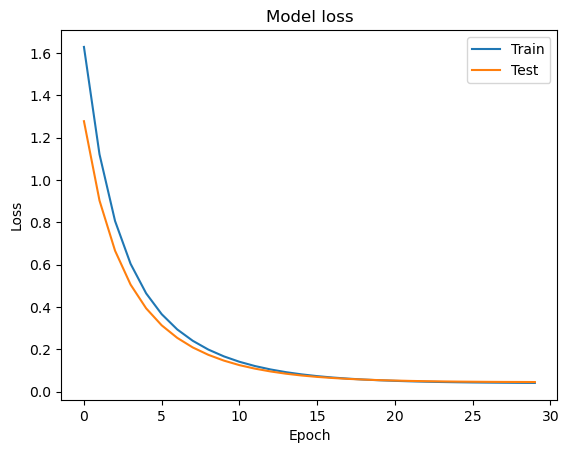

In [11]:
# look into training history
# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='best')
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


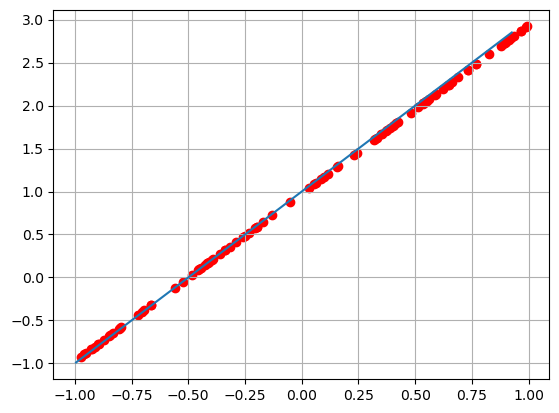

In [12]:
x_predicted = np.random.uniform(-1, 1, 100)
y_predicted = model.predict(x_predicted)
plt.scatter(x_predicted, y_predicted,color='r')
plt.plot(x_valid, y_target)
plt.grid(True)
plt.show()

### Exercise 11.1

In order to make practice with NN, explore how does the previous linear regression depend on the number of epochs, $N_{\mathrm{epochs}}$, the number of data points $N_{\mathrm{train}}$ and on the noise $\sigma$. Try to improve the previous result operating on these parameters.

### Exercise 11.2

Try to extend the model to obtain a reasonable fit of the following polynomial of order 3:

$$
f(x)=4-3x-2x^2+3x^3
$$
for $x \in [-1,1]$.

Find good (& reasonable) choices for:

- the number of layers
- the number of neurons in each layer
- the activation function
- the optimizer
- the loss function
  
Check your NN model by seeing how well your fits predict newly generated test data (including on data outside the range you fit. How well do your NN do on points in the range of $x$ where you trained the model? How about points outside the original training data set? 
Summarize what you have learned about the relationship between model complexity (number of parameters), goodness of fit on training data, and the ability to predict well.

### Exercise 11.3
  
Try to extend the model to fit a simple trigonometric 2D function such as $f(x,y) = \sin(x^2+y^2)$ in the range $x \in [-3/2,3/2]$ and $y \in [-3/2,3/2]$.

Ideas to meditate on these exercises and judge your results can be found <a href=https://xkcd.com/2048/>here</a>

## **Solution**
## Exercise 11.1 

We systematically investigate how the regression performance and generalization capability depend on:
1. **Gaussian noise level $\sigma$** (from noiseless data up to high-noise regimes).
2. **Number of training points $N_{\text{train}}$**.
3. **Training duration (number of epochs $N_{\text{epochs}}$)**.

Below, we begin the analysis by varying the noise amplitude $\sigma \in \{0, 0.2, 0.5, 1.0, 2.0\}$ while keeping $N_{\text{train}} = 500$ and $N_{\text{epochs}} = 30$ fixed.

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


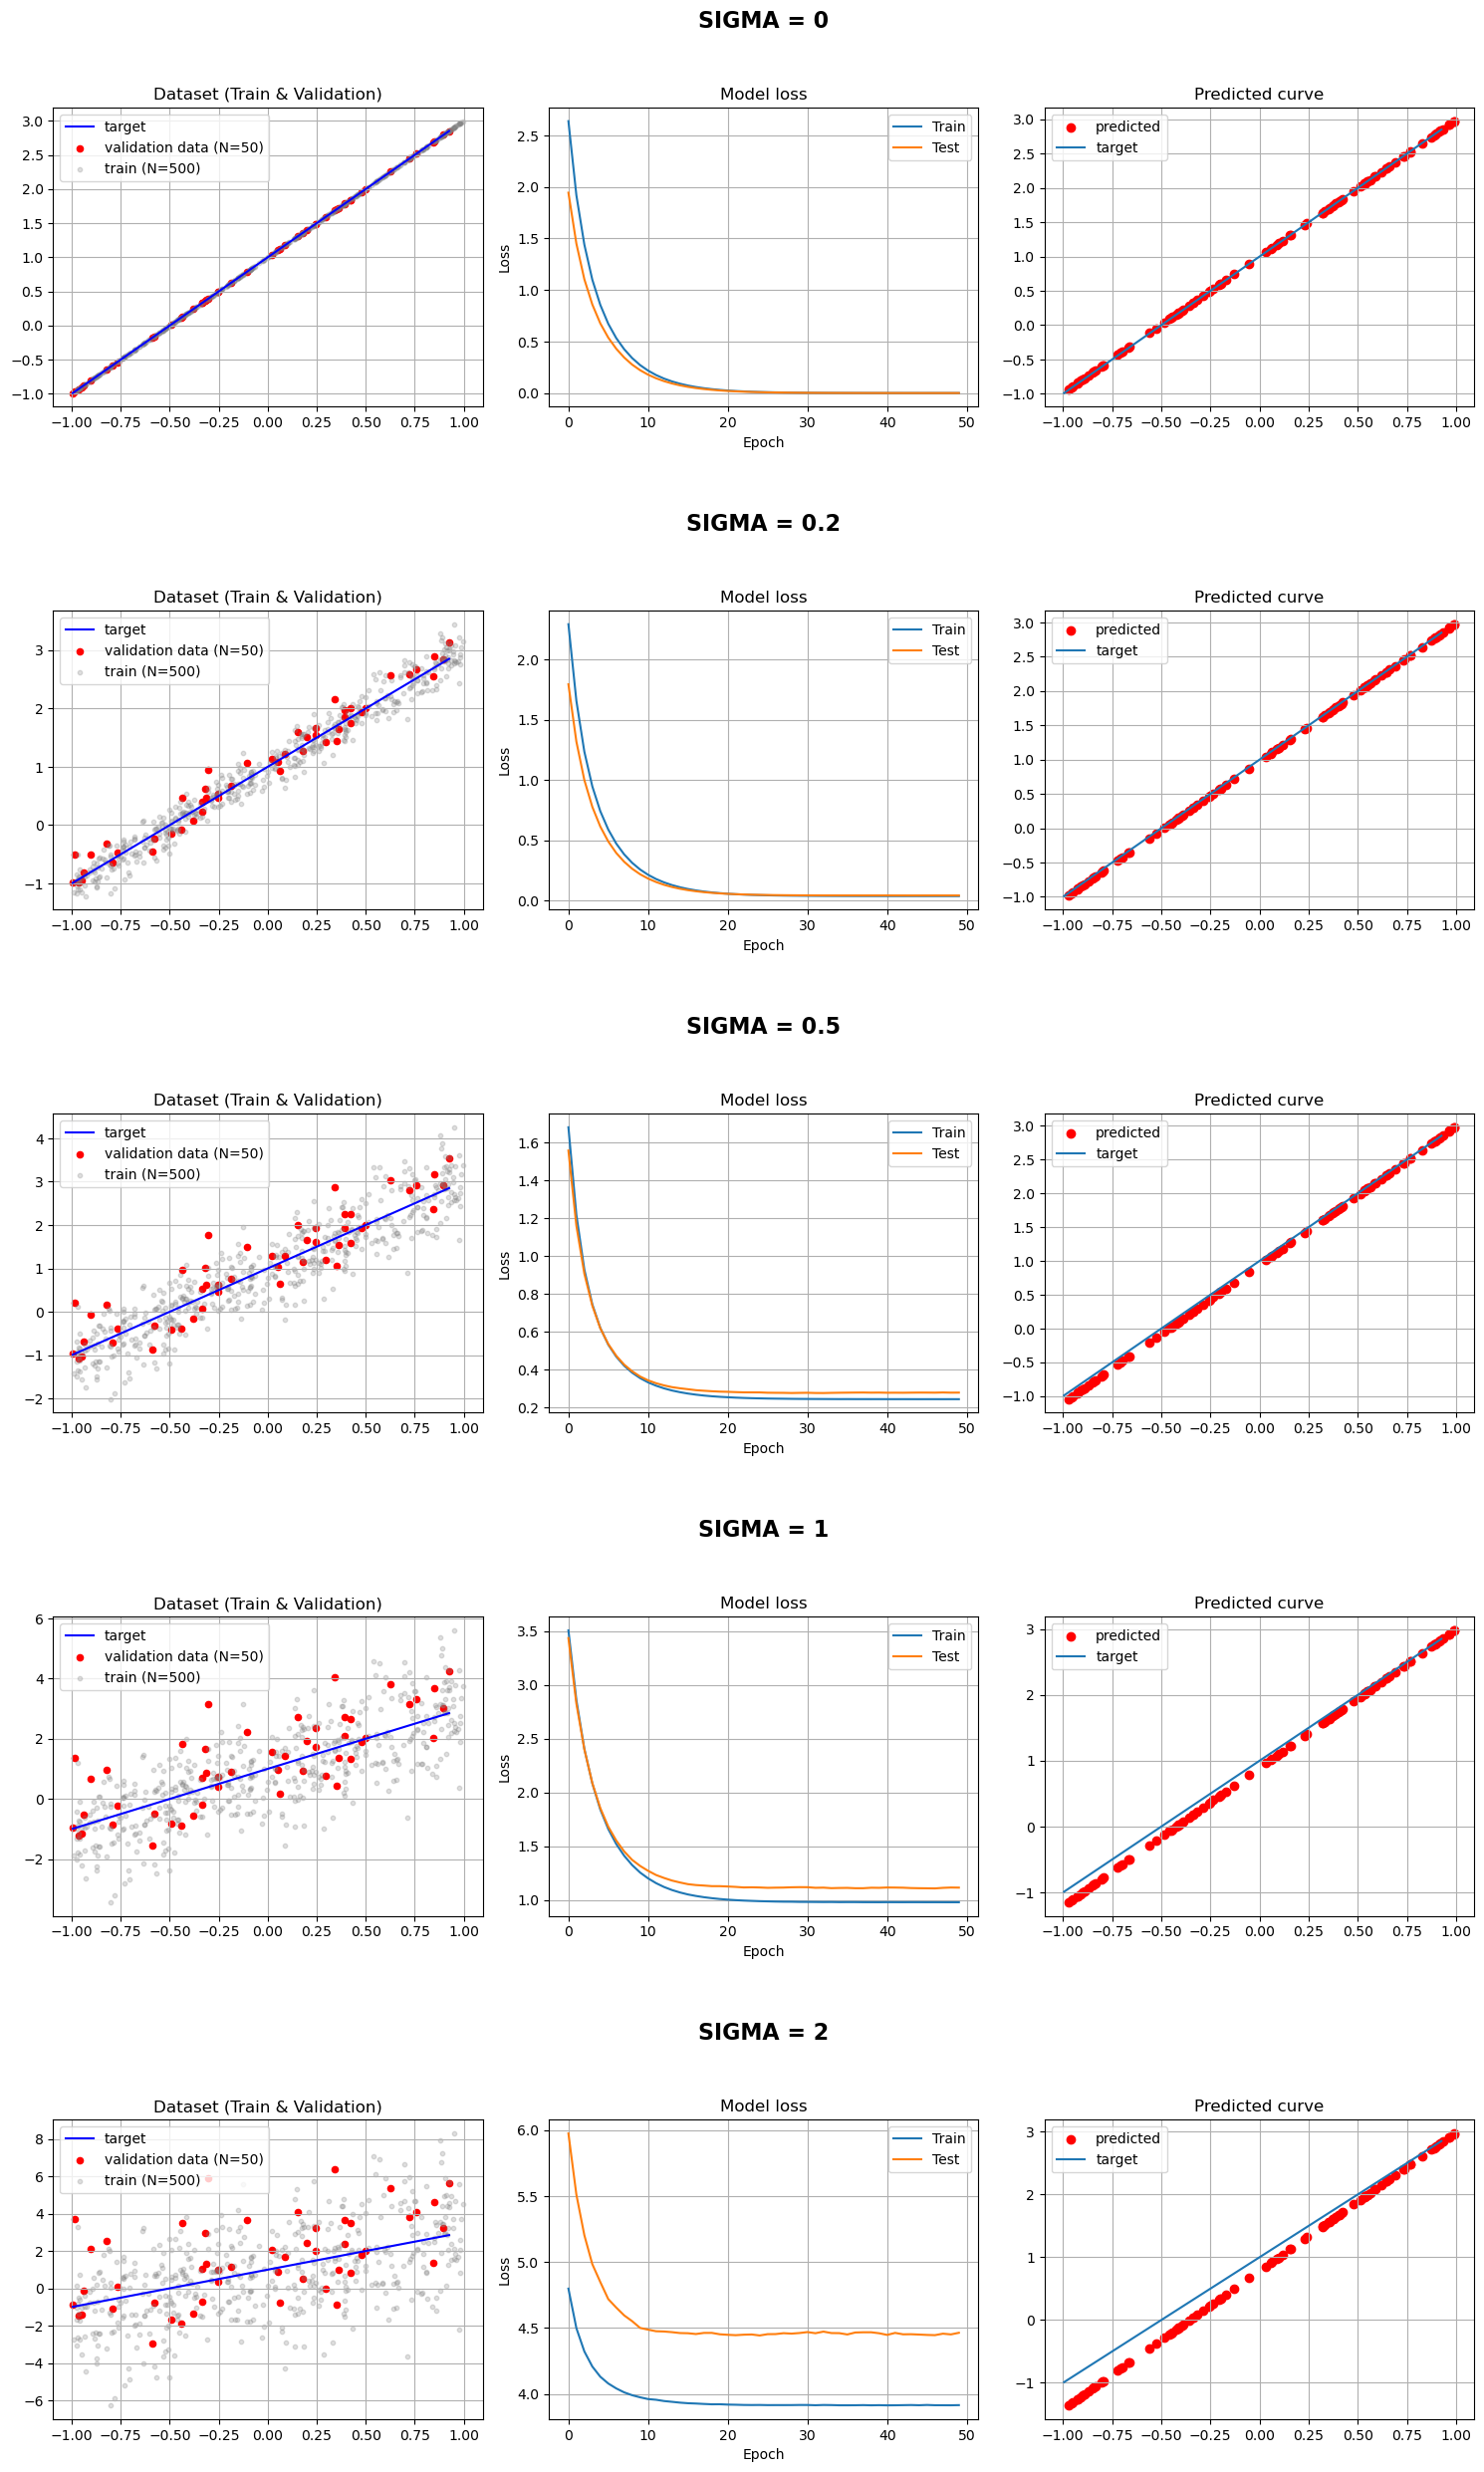

In [ ]:
sigmas = [0, 0.2, 0.5, 1, 2]
fig, axs = plt.subplots(nrows=len(sigmas), ncols=3, figsize=(15, 5*len(sigmas)))

for i, sigma in enumerate(sigmas):

     np.random.seed(0)
     x_train = np.random.uniform(-1, 1, 500)
     x_valid = np.random.uniform(-1, 1, 50)
     x_valid.sort()
     y_target = m * x_valid + b

     y_train = np.random.normal(m * x_train + b, sigma) # actual measures from which we want to guess regression parameters
     y_valid = np.random.normal(m * x_valid + b, sigma)

     axs[i, 0].plot(x_valid, y_target, label='target', color='blue')
     axs[i, 0].scatter(x_valid, y_valid, color='red', s=20, label='validation data (N=50)')
     axs[i, 0].scatter(x_train, y_train, color='gray', alpha=0.25, s=10, label='train (N=500)')
     axs[i, 0].set_title(f'Dataset (Train & Validation)')
     axs[i, 0].legend()
     axs[i, 0].grid(True)

     model = tf.keras.Sequential()
     model.add(Input(shape=(1,)))
     model.add(Dense(1))
     model.compile(optimizer='sgd', loss='mse', metrics=['mse'])
     history = model.fit(x=x_train, y=y_train, 
               batch_size=32, epochs=50,
               shuffle=True,
               validation_data=(x_valid, y_valid), verbose=0)
     
     axs[i, 1].plot(history.history['loss'])
     axs[i, 1].plot(history.history['val_loss'])
     axs[i, 1].set_title('Model loss')
     axs[i, 1].set_xlabel('Epoch')
     axs[i, 1].set_ylabel('Loss')
     axs[i, 1].legend(['Train', 'Test'], loc='best')
     axs[i, 1].grid(True)

     axs[i, 1].text(0.5, 1.25, f'SIGMA = {sigma}', 
                    transform=axs[i, 1].transAxes, 
                    fontsize=16, fontweight='bold', 
                    ha='center', va='bottom', color='black')

     x_predicted = np.random.uniform(-1, 1, 100)
     y_predicted = model.predict(x_predicted)
     axs[i, 2].scatter(x_predicted, y_predicted,color='r', label='predicted')
     axs[i, 2].plot(x_valid, y_target, label='target')
     axs[i, 2].set_title('Predicted curve')
     axs[i, 2].grid(True)
     axs[i, 2].legend()
     
plt.tight_layout(h_pad=4.0)
plt.show()



### Impact of Gaussian Noise ($\sigma$)

As the noise level $\sigma$ increases, we observe a clear deterioration in the quality of the fit. While the loss drops asymptotically toward zero in the noiseless case ($\sigma = 0$), larger noise amplitudes cause the loss to plateau around the irreducible noise variance, $\text{MSE} \approx \sigma^2$. 

At very low noise ($\sigma = 0.2$), the points tightly follow the target line $y = 2x + 1$, making parameter estimation trivial. Conversely, for large values ($\sigma \ge 1.0$), statistical dispersion significantly degrades the accuracy of the recovered slope and intercept. 

Therefore, we choose **$\sigma = 0.5$** as the benchmark for the subsequent tests: it provides a realistic, non-trivial level of stochastic noise while keeping the linear trend clearly recognizable, allowing us to cleanly observe how variations in $N_{\text{train}}$ and $N_{\text{epochs}}$ impact network convergence.

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


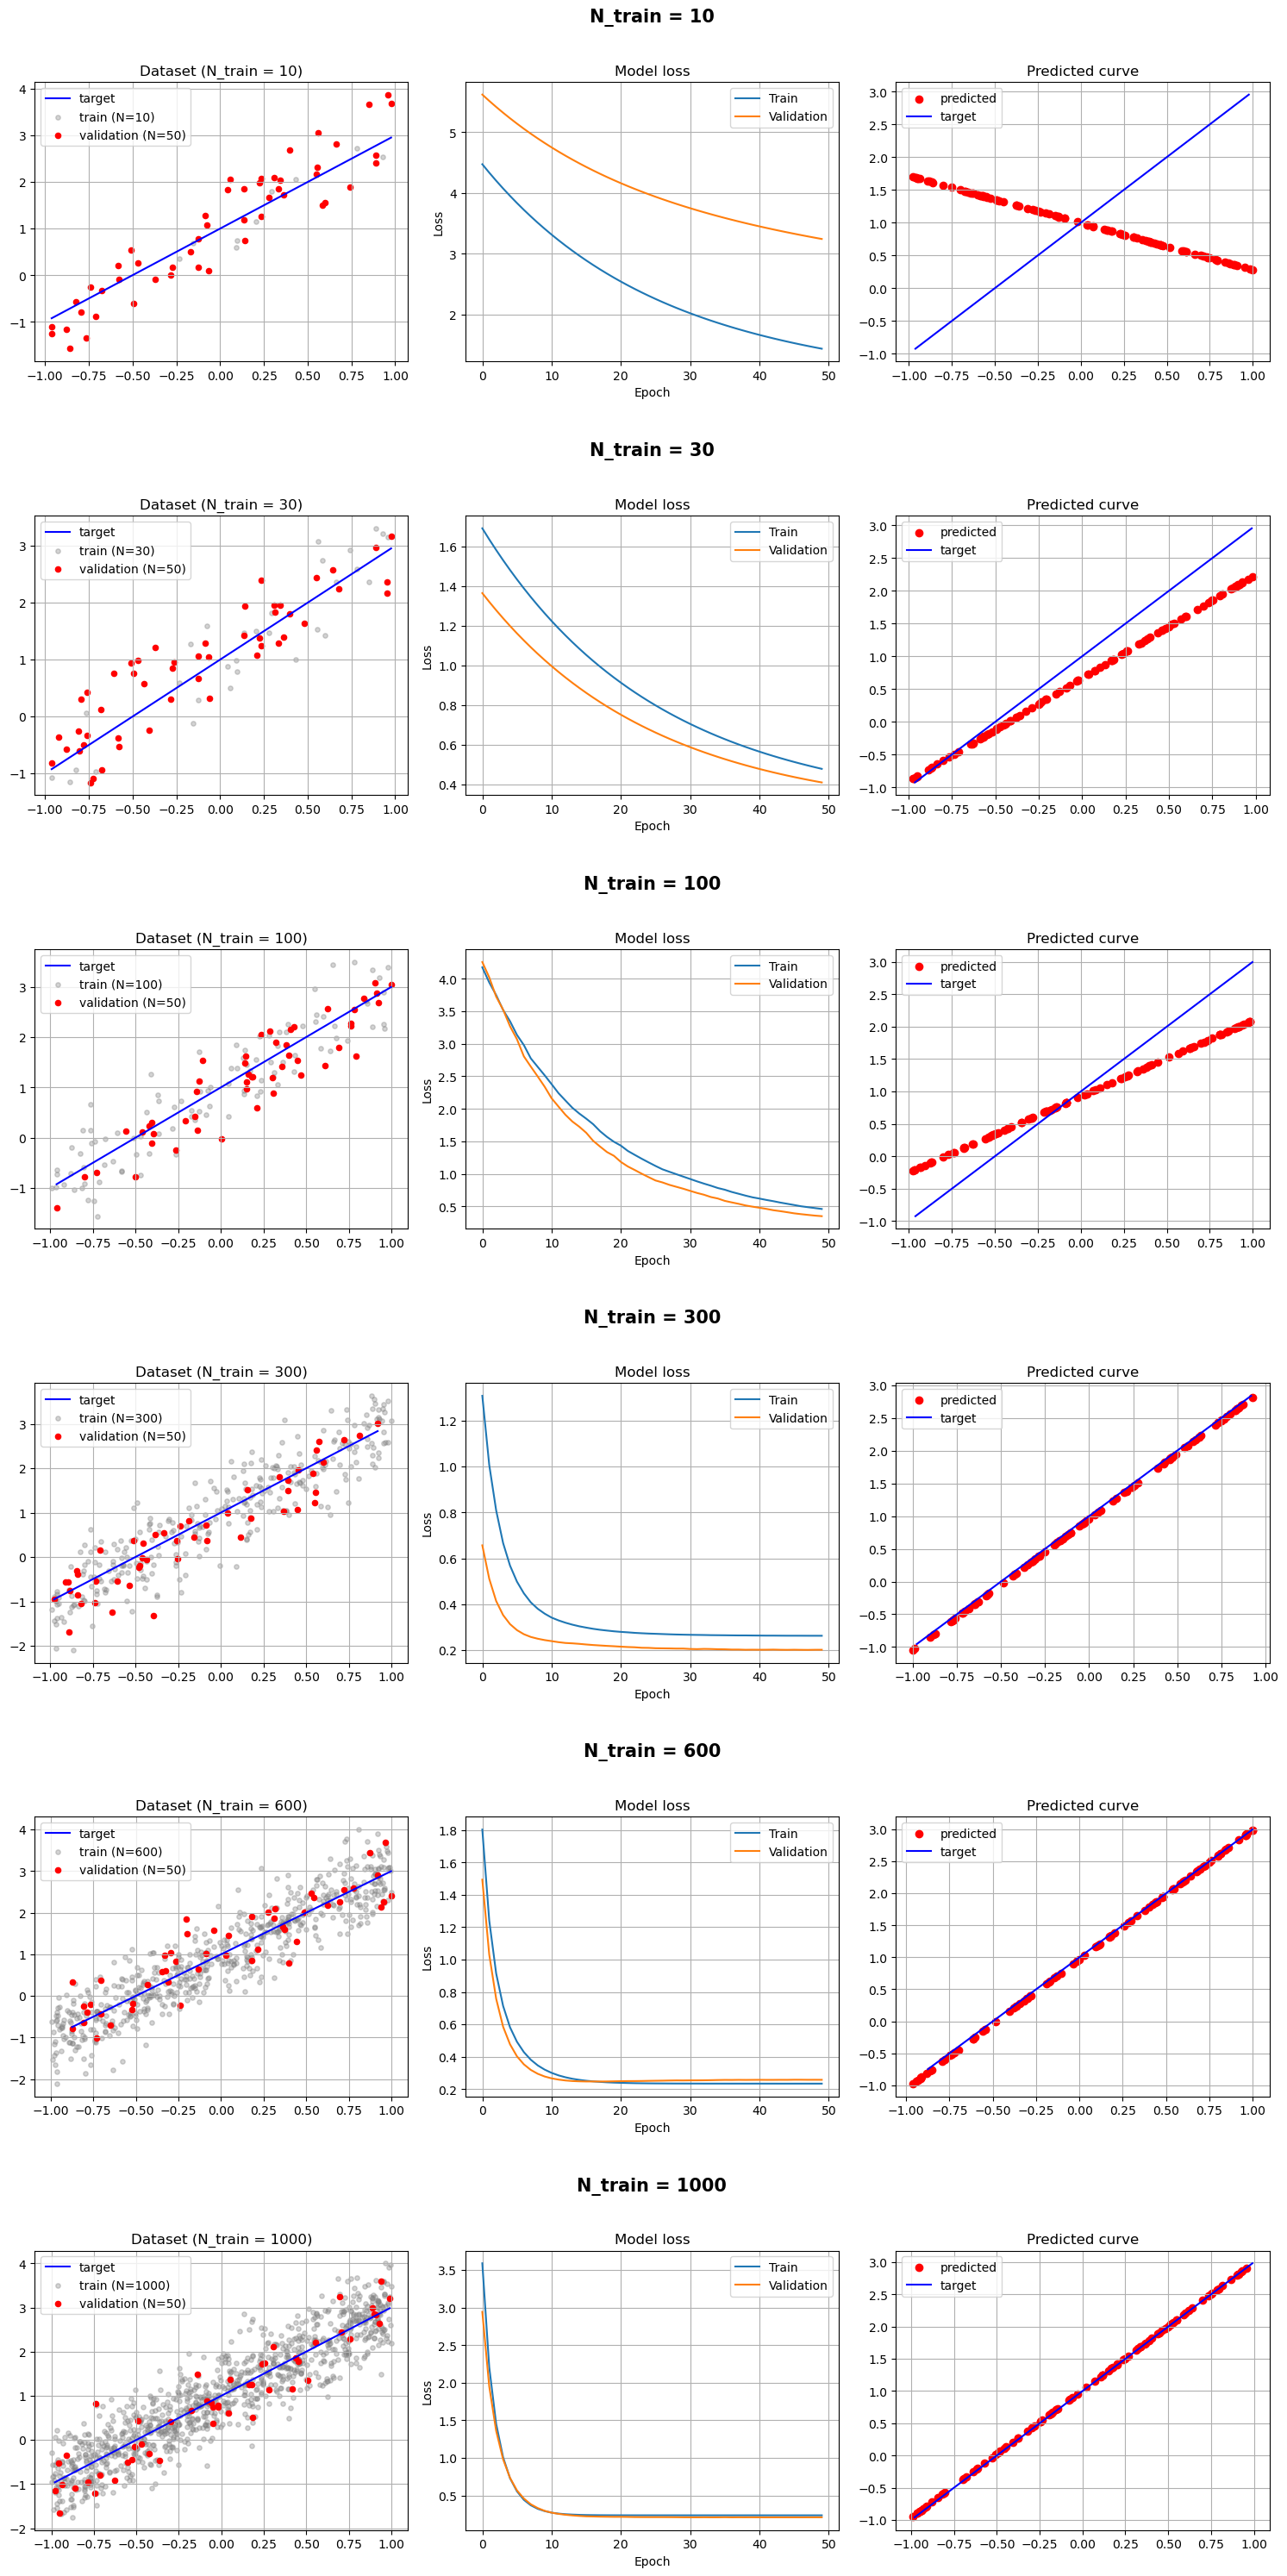

In [18]:
N_train = [10, 30, 100, 300, 600, 1000]
fixed_epochs = 50
sigma = 0.5

fig, axs = plt.subplots(nrows=len(N_train), ncols=3, figsize=(15, 5*len(N_train)))

for i, N in enumerate(N_train):
    np.random.seed(0)
    x_train = np.random.uniform(-1, 1, N)
    x_valid = np.random.uniform(-1, 1, 50)
    x_valid.sort()
    y_target = m * x_valid + b

    y_train = np.random.normal(m * x_train + b, sigma)
    y_valid = np.random.normal(m * x_valid + b, sigma)

    # 1. Mostra il dataset di training reale (N punti) e il validation
    axs[i, 0].plot(x_valid, y_target, label='target', color='blue')
    axs[i, 0].scatter(x_train, y_train, color='gray', alpha=0.35, s=15, label=f'train (N={N})')
    axs[i, 0].scatter(x_valid, y_valid, color='red', s=20, label='validation (N=50)')
    axs[i, 0].set_title(f'Dataset (N_train = {N})')
    axs[i, 0].legend()
    axs[i, 0].grid(True)

    # 2. Modello
    model = tf.keras.Sequential([
        Input(shape=(1,)),
        Dense(1)
    ])
    model.compile(optimizer='sgd', loss='mse', metrics=['mse'])
    history = model.fit(
        x=x_train, y=y_train, 
        batch_size=32, epochs=fixed_epochs,
        shuffle=True,
        validation_data=(x_valid, y_valid), 
        verbose=0
    )
     
    # 3. Loss
    axs[i, 1].plot(history.history['loss'], label='Train')
    axs[i, 1].plot(history.history['val_loss'], label='Validation')
    axs[i, 1].set_title('Model loss')
    axs[i, 1].set_xlabel('Epoch')
    axs[i, 1].set_ylabel('Loss')
    axs[i, 1].legend(loc='best')
    axs[i, 1].grid(True)
    axs[i, 1].text(0.5, 1.20, f'N_train = {N}', 
                   transform=axs[i, 1].transAxes, 
                   fontsize=15, fontweight='bold', 
                   ha='center', va='bottom', color='black')

    # 4. Predizioni
    x_predicted = np.random.uniform(-1, 1, 100)
    y_predicted = model.predict(x_predicted)
    axs[i, 2].scatter(x_predicted, y_predicted, color='r', label='predicted')
    axs[i, 2].plot(x_valid, y_target, label='target', color='blue')
    axs[i, 2].set_title('Predicted curve')
    axs[i, 2].grid(True)
    axs[i, 2].legend()
     
plt.tight_layout(h_pad=3.5)
plt.show()

N =  300 | Estimated m = 1.8811 (target 2.0) | b = 0.9471 (target 1.0)
N =  600 | Estimated m = 1.9265 (target 2.0) | b = 0.9800 (target 1.0)
N = 1000 | Estimated m = 1.9781 (target 2.0) | b = 1.0158 (target 1.0)


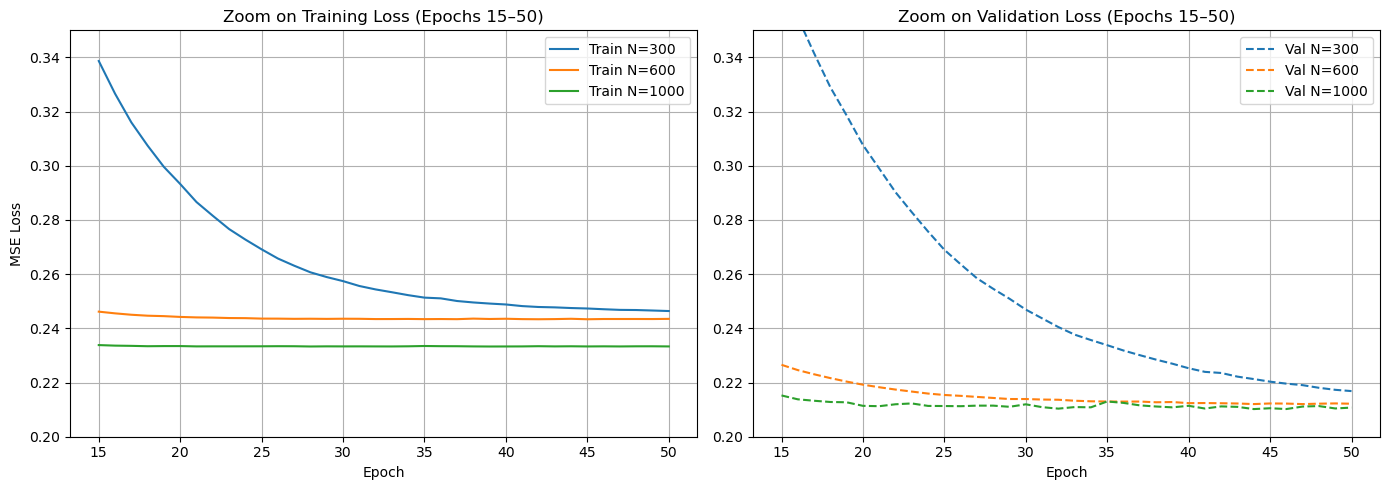

In [20]:
N_zoom = [300, 600, 1000]
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

for N in N_zoom:
    np.random.seed(0)
    x_tr = np.random.uniform(-1, 1, N)
    y_tr = np.random.normal(m * x_tr + b, 0.5)
    
    # Modello
    mod = tf.keras.Sequential([Input(shape=(1,)), Dense(1)])
    mod.compile(optimizer='sgd', loss='mse')
    hist = mod.fit(x_tr, y_tr, batch_size=32, epochs=50, validation_data=(x_valid, y_valid), verbose=0)
    
    # Estrai parametri fittati
    w, bias = mod.get_weights()
    print(f"N = {N:4d} | Estimated m = {w[0][0]:.4f} (target 2.0) | b = {bias[0]:.4f} (target 1.0)")
    
    # Plot loss zoomata (epoche 15-50)
    axs[0].plot(range(15, 51), hist.history['loss'][14:], label=f'Train N={N}')
    axs[1].plot(range(15, 51), hist.history['val_loss'][14:], linestyle='--', label=f'Val N={N}')

axs[0].set_title('Zoom on Training Loss (Epochs 15–50)')
axs[0].set_ylim(0.20, 0.35)
axs[0].set_xlabel('Epoch')
axs[0].set_ylabel('MSE Loss')
axs[0].grid(True)
axs[0].legend()

axs[1].set_title('Zoom on Validation Loss (Epochs 15–50)')
axs[1].set_ylim(0.20, 0.35)
axs[1].set_xlabel('Epoch')
axs[1].grid(True)
axs[1].legend()

plt.tight_layout()
plt.show()

Reducing the size of the training dataset significantly slows down convergence, meaning the network requires more epochs to reach the plateau. With a fixed batch size of 32, smaller datasets perform far fewer parameter updates in each epoch compared to larger ones. Once converged, however, the final validation loss reaches comparable baseline values across all tested sizes.

Moreover, no significant overfitting is observed. Because the network consists of just a single neuron with two trainable parameters (weight and bias), it lacks the expressive capacity to memorize stochastic noise. Any minor oscillations or mild increases in the validation loss curves are merely statistical fluctuations stemming from the small validation sample size ($N_{\text{valid}} = 50$), rather than actual loss of generalization.

## Exercise 11.2

### **Methodology: Sequential Hyperparameter Tuning**

Performing an exhaustive grid search across all possible combinations of layers, neurons, activation functions, and optimizers would require training and plotting over a hundred distinct models, making visual inspection impractical and computationally redundant. 

Instead, I adopt a **sequential, step-by-step approach**: I isolate and vary one hyperparameter group at a time while keeping the others fixed at reasonable baseline values, progressively locking in the best configuration at each stage.

### Layers and Neurons
I fixed
* $\sigma = 0.2$
* $N_{train} = 1000$
* activation: relu 
* optimizer: adam
ad we look at 5 different configuration of neurons and layers. 

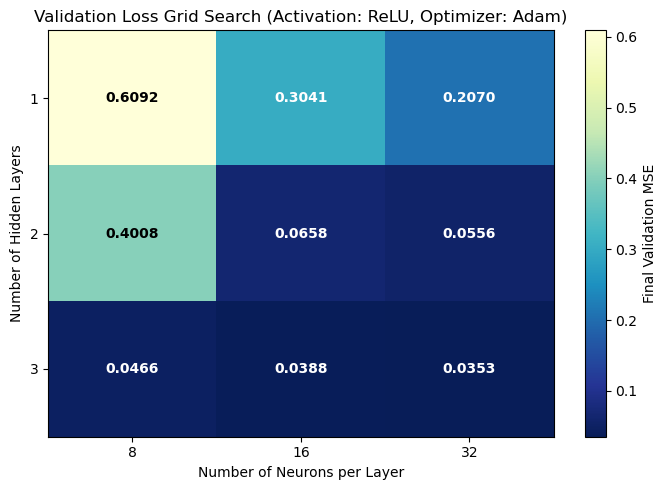

In [24]:
# Parametri del polinomio f(x) = 4 - 3x - 2x^2 + 3x^3
def f_poly(x):
    return 4 - 3*x - 2*(x**2) + 3*(x**3)

sigma = 0.2
N_train = 1000
epochs = 50

np.random.seed(0)
x_train = np.random.uniform(-1, 1, N_train)
x_valid = np.random.uniform(-1, 1, 100)
x_valid.sort()

y_target = f_poly(x_valid)
y_train = np.random.normal(f_poly(x_train), sigma)
y_valid = np.random.normal(f_poly(x_valid), sigma)

layers_list = [1, 2, 3]
neurons_list = [8, 16, 32]
val_loss_grid = np.zeros((len(layers_list), len(neurons_list)))

for i, n_layers in enumerate(layers_list):
    for j, n_neurons in enumerate(neurons_list):
        tf.keras.backend.clear_session()
        np.random.seed(0)
        tf.random.set_seed(0)
        
        model = tf.keras.Sequential()
        model.add(Input(shape=(1,)))
        for _ in range(n_layers):
            model.add(Dense(n_neurons, activation='relu'))
        model.add(Dense(1))
        
        model.compile(optimizer='adam', loss='mse')
        history = model.fit(x_train, y_train, batch_size=32, epochs=epochs,
                            validation_data=(x_valid, y_valid), verbose=0)
        
        # Media delle ultime 5 epoche di val_loss per stabilità
        val_loss_grid[i, j] = np.mean(history.history['val_loss'][-5:])

# Plot della Heatmap con Matplotlib puro
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(val_loss_grid, cmap='YlGnBu_r', aspect='auto')

# Barra colori
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Final Validation MSE')

# Assi ed etichette
ax.set_xticks(np.arange(len(neurons_list)))
ax.set_yticks(np.arange(len(layers_list)))
ax.set_xticklabels(neurons_list)
ax.set_yticklabels(layers_list)
ax.set_xlabel('Number of Neurons per Layer')
ax.set_ylabel('Number of Hidden Layers')
ax.set_title('Validation Loss Grid Search (Activation: ReLU, Optimizer: Adam)')

# Annotazioni numeriche dentro le celle
thresh = (val_loss_grid.max() + val_loss_grid.min()) / 2.0
for i in range(len(layers_list)):
    for j in range(len(neurons_list)):
        color = "white" if val_loss_grid[i, j] < thresh else "black"
        ax.text(j, i, f"{val_loss_grid[i, j]:.4f}",
                ha="center", va="center", color=color, fontweight="bold")

plt.tight_layout()
plt.show()

To systematically explore the model complexity without plotting nine separate training curves, the heatmap above reports the final validation MSE across all combinations of hidden layers ($1, 2, 3$) and neurons per layer ($8, 16, 32$).

Since the dataset is generated with Gaussian noise $\sigma = 0.2$, the theoretical minimum irreducible error is $\text{MSE}_{\text{min}} \approx \sigma^2 = 0.04$. Looking at the grid:
* **1 Hidden Layer:** Regardless of the number of neurons, a single hidden layer fails to reach the noise floor ($\text{MSE} \ge 0.20$), clearly underfitting the cubic polynomial.
* **2 and 3 Hidden Layers:** Moving to `(2 layers, 16 neurons)` causes a sharp drop in the validation loss down to $0.0658$, while `(3 layers, 16 neurons)` hits the theoretical noise limit ($0.0388 \approx \sigma^2$). 
* **Model Selection:** Increasing the width to 32 neurons (e.g., `(3, 32)` with $\text{MSE} = 0.0353$) increases the number of trainable parameters dramatically (from $\sim 300\text{–}600$ up to $>2200$) for a negligible gain that merely reflects finite-sample fluctuations below $\sigma^2$. We therefore select **2 layers, 16 neurons** as the optimal balance between expressive power and computational efficiency.

### Single-Parameter Exploration: Activation Functions & Optimizers

Having determined our baseline architecture (2 hidden layers with 16 neurons), we now analyze the sensitivity of the model to the remaining hyperparameters individually. Instead of a full multidimensional grid search, we vary one parameter at a time while keeping the rest fixed:
1. **Activation functions** (testing `linear`, `sigmoid`, `tanh`, `relu`, and `elu`).
2. **Optimizers** (testing `sgd`, `rmsprop`, and `adam`).

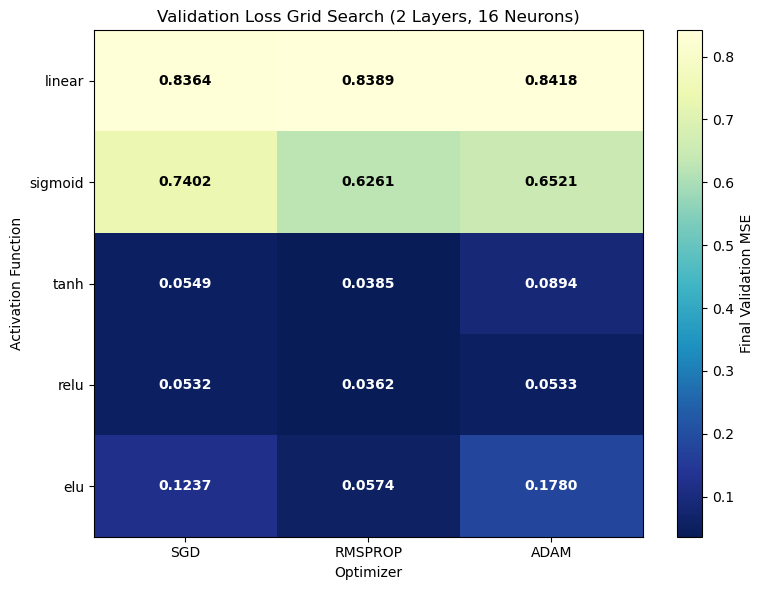

In [ ]:
activations = ['linear', 'sigmoid', 'tanh', 'relu', 'elu']
optimizers = ['sgd', 'rmsprop', 'adam']
val_loss_act_opt = np.zeros((len(activations), len(optimizers)))

n_layers, n_neurons = 2, 16

for i, act in enumerate(activations):
    for j, opt in enumerate(optimizers):
        tf.keras.backend.clear_session()
        np.random.seed(0)
        tf.random.set_seed(0)
        
        model = tf.keras.Sequential()
        model.add(Input(shape=(1,)))
        for _ in range(n_layers):
            model.add(Dense(n_neurons, activation=act))
        model.add(Dense(1))
        
        model.compile(optimizer=opt, loss='mse')
        history = model.fit(x_train, y_train, batch_size=32, epochs=epochs,
                            validation_data=(x_valid, y_valid), verbose=0)
        
        val_loss_act_opt[i, j] = np.mean(history.history['val_loss'][-5:])

# Plot della Heatmap (Attivazioni vs Ottimizzatori)
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(val_loss_act_opt, cmap='YlGnBu_r', aspect='auto')

cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Final Validation MSE')

ax.set_xticks(np.arange(len(optimizers)))
ax.set_yticks(np.arange(len(activations)))
ax.set_xticklabels([o.upper() for o in optimizers])
ax.set_yticklabels(activations)
ax.set_xlabel('Optimizer')
ax.set_ylabel('Activation Function')
ax.set_title(f'Validation Loss Grid Search ({n_layers} Layers, {n_neurons} Neurons)')

thresh = (val_loss_act_opt.max() + val_loss_act_opt.min()) / 2.0
for i in range(len(activations)):
    for j in range(len(optimizers)):
        color = "white" if val_loss_act_opt[i, j] < thresh else "black"
        ax.text(j, i, f"{val_loss_act_opt[i, j]:.4f}",
                ha="center", va="center", color=color, fontweight="bold")

plt.tight_layout()
plt.show()

### Activation Functions and Optimizers Grid Search

The heatmap above displays the final validation MSE across various combinations of activation functions and optimizers (with architecture fixed at 2 hidden layers and 16 neurons):

* **Activation Performance:** Non-linear activations (`ReLU`, `tanh`, and `elu`) successfully capture the cubic curvature, driving the validation loss down to the theoretical noise floor ($\text{MSE} \approx \sigma^2 = 0.04$). Conversely, `linear` and `sigmoid` fail to fit the non-linear target within 50 epochs, resulting in high validation errors ($\ge 0.60$).
* **Optimizer Impact:** Adaptive gradient methods like **`RMSprop`** and **`Adam`** consistently outperform standard `SGD`, accelerating convergence and preventing the model from getting stuck in suboptimal local minima.
* **Optimal Selection:** The combination of **`ReLU` activation** with **`RMSprop` optimizer** achieves the best trade-off, yielding a minimal validation MSE of **$0.0362$**.

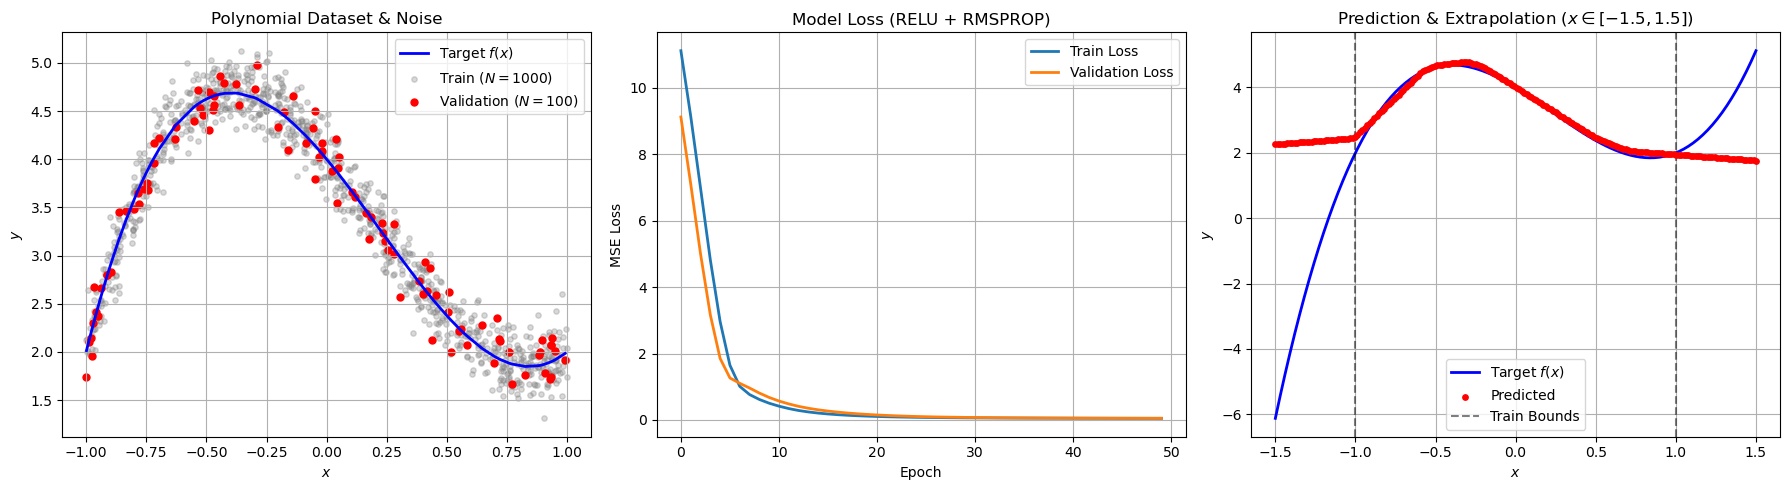

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense
import matplotlib.pyplot as plt

# 1. Definizione del polinomio target f(x) = 4 - 3x - 2x^2 + 3x^3
def f_poly(x):
    return 4 - 3*x - 2*(x**2) + 3*(x**3)

# 2. Parametri ottimali scelti dalle grid search
sigma = 0.2
N_train = 1000
epochs = 50
n_layers = 2
n_neurons = 16
activation_fn = 'relu'      
optimizer_choice = 'rmsprop' 

# Generazione dati con rumore gaussiano
np.random.seed(0)
x_train = np.random.uniform(-1, 1, N_train)
x_valid = np.random.uniform(-1, 1, 100)
x_valid.sort()

y_target = f_poly(x_valid)
y_train = np.random.normal(f_poly(x_train), sigma)
y_valid = np.random.normal(f_poly(x_valid), sigma)

# 3. Costruzione e training del modello ottimale
tf.keras.backend.clear_session()
np.random.seed(0)
tf.random.set_seed(0)

model = tf.keras.Sequential()
model.add(Input(shape=(1,)))
for _ in range(n_layers):
    model.add(Dense(n_neurons, activation=activation_fn))
model.add(Dense(1)) # Output layer lineare per regressione

model.compile(optimizer=optimizer_choice, loss='mse', metrics=['mse'])

history = model.fit(
    x=x_train, y=y_train,
    batch_size=32, epochs=epochs,
    shuffle=True,
    validation_data=(x_valid, y_valid),
    verbose=0
)

# 4. Creazione del multi-grafico a 3 pannelli
fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))

# Pannello 1: Dataset di Training e Validazione con il Target
axs[0].plot(x_valid, y_target, label='Target $f(x)$', color='blue', lw=2)
axs[0].scatter(x_train, y_train, color='gray', alpha=0.3, s=15, label=f'Train ($N={N_train}$)')
axs[0].scatter(x_valid, y_valid, color='red', s=25, label='Validation ($N=100$)')
axs[0].set_title('Polynomial Dataset & Noise')
axs[0].set_xlabel('$x$')
axs[0].set_ylabel('$y$')
axs[0].legend(loc='best')
axs[0].grid(True)

# Pannello 2: Curve di Loss (Training e Validation)
axs[1].plot(history.history['loss'], label='Train Loss', lw=2)
axs[1].plot(history.history['val_loss'], label='Validation Loss', lw=2)
axs[1].set_title(f'Model Loss ({activation_fn.upper()} + {optimizer_choice.upper()})')
axs[1].set_xlabel('Epoch')
axs[1].set_ylabel('MSE Loss')
axs[1].legend(loc='best')
axs[1].grid(True)

# Pannello 3: Curva Predetta ed Estrapolazione fuori da [-1, 1]
x_ext = np.linspace(-1.5, 1.5, 200)
y_ext_target = f_poly(x_ext)
y_predicted = model.predict(x_ext, verbose=0)

axs[2].plot(x_ext, y_ext_target, label='Target $f(x)$', color='blue', lw=2)
axs[2].scatter(x_ext, y_predicted, color='red', s=15, label='Predicted', zorder=5)
axs[2].axvline(-1.0, color='k', linestyle='--', alpha=0.5, label='Train Bounds')
axs[2].axvline(1.0, color='k', linestyle='--', alpha=0.5)
axs[2].set_title(r'Prediction & Extrapolation ($x \in [-1.5, 1.5]$)')
axs[2].set_xlabel('$x$')
axs[2].set_ylabel('$y$')
axs[2].legend(loc='best')
axs[2].grid(True)

plt.tight_layout()
plt.show()

Neural networks act as powerful local function approximators within the support of the training distribution, but they exhibit poor generalization outside of it. Because the dataset is strictly bounded to $x \in [-1, 1]$, the network learns the cubic trend only locally. 

When evaluated beyond the training domain ($|x| > 1$), the model fails to extrapolate the true underlying analytical polynomial ($3x^3$). Instead, due to the piecewise linear nature of the ReLU activation functions, predictions default to a linear extrapolation based on the boundary gradients, highlighting that the network learns data-driven approximations rather than symbolic mathematical laws.

## Exercise 11.3
We now extend our regression analysis from 1D polynomial fitting to a more complex 2D problem: approximating the trigonometric function:
$$f(x, y) = \sin\left(x^2 + y^2\right), \quad x, y \in \left[-\frac{3}{2}, \frac{3}{2}\right]$$

This transition introduces significant challenges that require re-evaluating our hyperparameters:
* **Increased Dimensionality:** The input space expands from a single coordinate ($x$) to a 2D coordinate vector $(x, y)$, meaning the network's input layer must be adjusted to accept shape `(2,)`.
* **Higher Complexity & Non-Linearity:** Unlike the monotonic or cubic trends of previous exercises, $\sin(x^2 + y^2)$ exhibits concentric, highly non-linear oscillations with rapid variations across the domain.

To determine the optimal architecture capable of mapping this complex surface, we perform a new systematic **Grid Search** over the number of hidden layers and neurons per layer, ensuring the network possesses sufficient expressive capacity before evaluating its predictive performance.

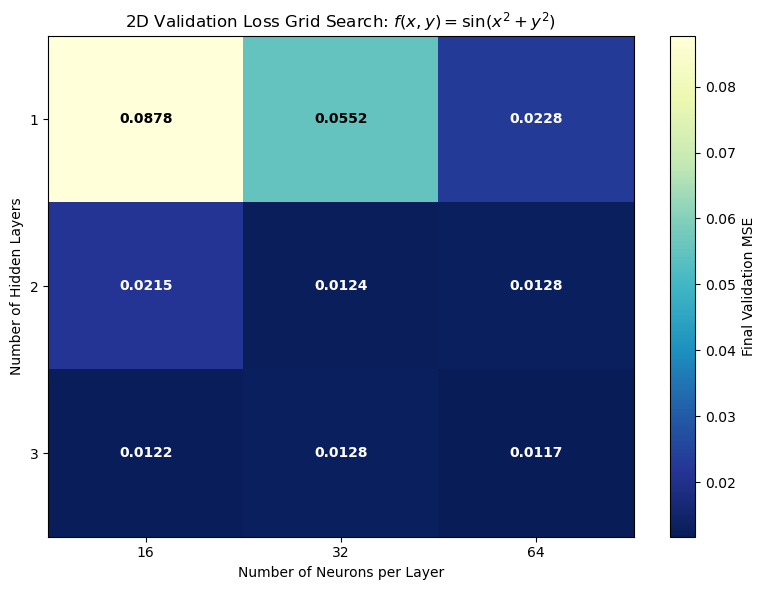

In [31]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense
import matplotlib.pyplot as plt

# 1. Definizione della funzione target 2D: f(x, y) = sin(x^2 + y^2)
def f_2d(x, y):
    return np.sin(x**2 + y**2)

# Parametri dell'esperimento
sigma = 0.1       # Rumore gaussiano sui dati
N_train = 2000    # Campioni di training (più alti per il 2D)
N_valid = 400     # Campioni di validazione
epochs = 50       # Epoche di training

# Generazione del dataset 2D
np.random.seed(0)
x_train = np.random.uniform(-1.5, 1.5, N_train)
y_train_coord = np.random.uniform(-1.5, 1.5, N_train)
X_train = np.column_stack((x_train, y_train_coord)) # Shape: (N_train, 2)
Z_train = np.random.normal(f_2d(x_train, y_train_coord), sigma)

x_valid = np.random.uniform(-1.5, 1.5, N_valid)
y_valid_coord = np.random.uniform(-1.5, 1.5, N_valid)
X_valid = np.column_stack((x_valid, y_valid_coord)) # Shape: (N_valid, 2)
Z_valid = np.random.normal(f_2d(x_valid, y_valid_coord), sigma)

# 2. Definizione della griglia per la Grid Search
layers_list = [1, 2, 3]
neurons_list = [16, 32, 64]
val_loss_grid = np.zeros((len(layers_list), len(neurons_list)))

# 3. Ciclo di esplorazione sistematica (Grid Search)
for i, n_layers in enumerate(layers_list):
    for j, n_neurons in enumerate(neurons_list):
        tf.keras.backend.clear_session()
        np.random.seed(0)
        tf.random.set_seed(0)
        
        model = tf.keras.Sequential()
        model.add(Input(shape=(2,))) # Input a 2 coordinate (x, y)
        for _ in range(n_layers):
            model.add(Dense(n_neurons, activation='relu'))
        model.add(Dense(1)) # Output scalare Z
        
        model.compile(optimizer='rmsprop', loss='mse')
        
        history = model.fit(
            X_train, Z_train,
            batch_size=32,
            epochs=epochs,
            validation_data=(X_valid, Z_valid),
            verbose=0
        )
        
        # Media delle ultime 5 epoche per stabilità della val_loss
        val_loss_grid[i, j] = np.mean(history.history['val_loss'][-5:])

# 4. Plot della Heatmap con Matplotlib puro
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(val_loss_grid, cmap='YlGnBu_r', aspect='auto')

# Barra dei colori
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Final Validation MSE')

# Assi ed etichette
ax.set_xticks(np.arange(len(neurons_list)))
ax.set_yticks(np.arange(len(layers_list)))
ax.set_xticklabels(neurons_list)
ax.set_yticklabels(layers_list)
ax.set_xlabel('Number of Neurons per Layer')
ax.set_ylabel('Number of Hidden Layers')
ax.set_title(r'2D Validation Loss Grid Search: $f(x,y)=\sin(x^2+y^2)$')

# Annotazioni numeriche dentro le celle
thresh = (val_loss_grid.max() + val_loss_grid.min()) / 2.0
for i in range(len(layers_list)):
    for j in range(len(neurons_list)):
        color = "white" if val_loss_grid[i, j] < thresh else "black"
        ax.text(j, i, f"{val_loss_grid[i, j]:.4f}",
                ha="center", va="center", color=color, fontweight="bold")

plt.tight_layout()
plt.show()

Based on the systematic grid search across network capacities, the configuration of **2 hidden layers with 32 neurons per layer** has been selected as the optimal architecture. 

While deeper or wider models (such as 3 layers with 64 neurons) achieve a marginally lower validation MSE ($\approx 0.0117$ compared to $0.0124$), the $(2, 32)$ network captures the concentric oscillations of $\sin(x^2 + y^2)$ with high fidelity while remaining significantly more compact. This balanced architecture provides sufficient expressive capacity for the 2D surface without introducing unnecessary over-parameterization or computational overhead.

Training MSE (final epoch):   0.04288
Validation MSE (final epoch): 0.04309


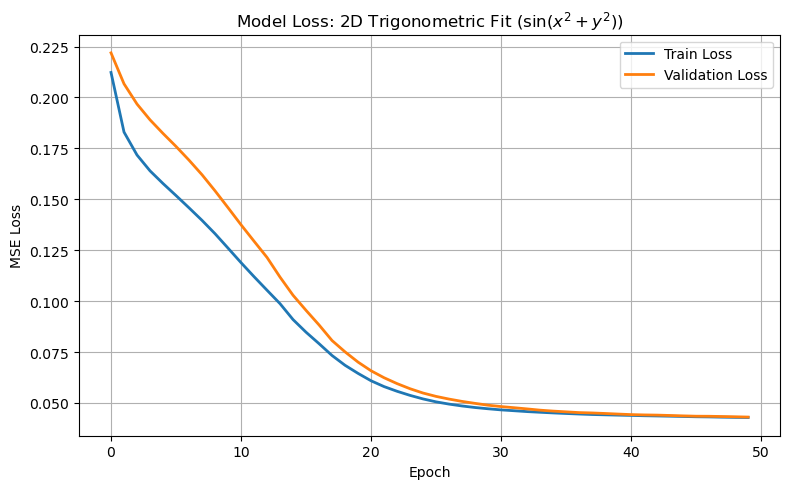

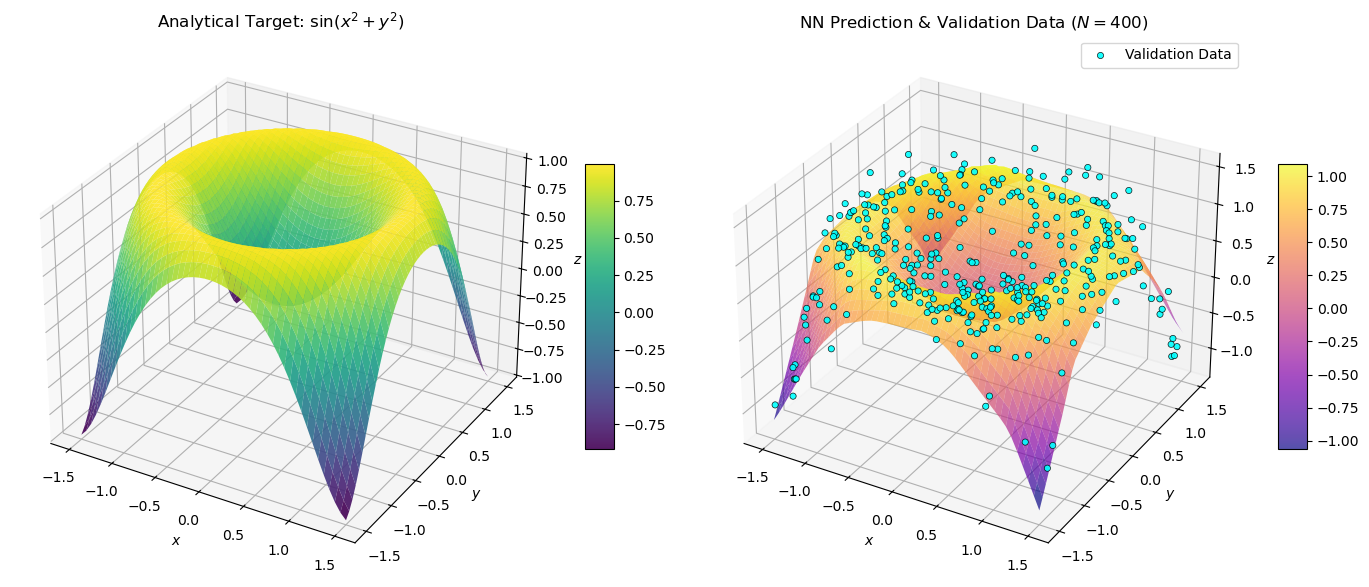

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense
import matplotlib.pyplot as plt

# 1. Definizione della funzione target 2D: f(x, y) = sin(x^2 + y^2)
def f_2d(x, y):
    return np.sin(x**2 + y**2)

# 2. Parametri dell'esperimento (configurazione definitiva)
sigma = 0.2          # Rumore gaussiano
N_train = 2000       # Campioni di training
N_valid = 400        # Campioni di validazione
epochs = 50          # Epoche di training
n_layers = 2         # Layer nascosti ottimali
n_neurons = 32       # Neuroni per layer ottimali
activation_fn = 'relu'
optimizer_choice = 'rmsprop'

# Generazione del dataset 2D
np.random.seed(0)
x_train = np.random.uniform(-1.5, 1.5, N_train)
y_train_coord = np.random.uniform(-1.5, 1.5, N_train)
X_train = np.column_stack((x_train, y_train_coord)) # Shape: (N_train, 2)
Z_train = np.random.normal(f_2d(x_train, y_train_coord), sigma)

x_valid = np.random.uniform(-1.5, 1.5, N_valid)
y_valid_coord = np.random.uniform(-1.5, 1.5, N_valid)
X_valid = np.column_stack((x_valid, y_valid_coord)) # Shape: (N_valid, 2)
Z_valid = np.random.normal(f_2d(x_valid, y_valid_coord), sigma)

# 3. Costruzione e training del modello definitivo
tf.keras.backend.clear_session()
np.random.seed(0)
tf.random.set_seed(0)

model = tf.keras.Sequential()
model.add(Input(shape=(2,))) # Input a 2 coordinate (x, y)
for _ in range(n_layers):
    model.add(Dense(n_neurons, activation=activation_fn))
model.add(Dense(1)) # Output scalare Z (regressione)

model.compile(optimizer=optimizer_choice, loss='mse', metrics=['mse'])

history = model.fit(
    X_train, Z_train,
    batch_size=32,
    epochs=epochs,
    shuffle=True,
    validation_data=(X_valid, Z_valid),
    verbose=0
)

# Stampa delle metriche finali
final_train_loss = history.history['loss'][-1]
final_val_loss = history.history['val_loss'][-1]
print(f"Training MSE (final epoch):   {final_train_loss:.5f}")
print(f"Validation MSE (final epoch): {final_val_loss:.5f}")

# 4. Plot delle curve di Loss per verificare la convergenza
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(history.history['loss'], label='Train Loss', lw=2)
ax.plot(history.history['val_loss'], label='Validation Loss', lw=2)
ax.set_title(r'Model Loss: 2D Trigonometric Fit ($\sin(x^2 + y^2)$)')
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE Loss')
ax.legend(loc='best')
ax.grid(True)
plt.tight_layout()
plt.show()

# 5. Visualizzazione 3D: Sinistra = Modello Teorico Puro | Destra = Predizione NN + Dati Reali
grid_size = 50
x_grid = np.linspace(-1.5, 1.5, grid_size)
y_grid = np.linspace(-1.5, 1.5, grid_size)
X_mesh, Y_mesh = np.meshgrid(x_grid, y_grid)

Z_true = f_2d(X_mesh, Y_mesh)
X_grid_flat = np.column_stack((X_mesh.ravel(), Y_mesh.ravel()))
Z_pred_flat = model.predict(X_grid_flat, verbose=0)
Z_pred = Z_pred_flat.reshape(X_mesh.shape)

fig = plt.figure(figsize=(14, 6))

# Pannello di sinistra: Solo la superficie teorica 
ax1 = fig.add_subplot(121, projection='3d')
surf1 = ax1.plot_surface(X_mesh, Y_mesh, Z_true, cmap='viridis', edgecolor='none', alpha=0.9)
ax1.set_title(r'Analytical Target: $\sin(x^2 + y^2)$')
ax1.set_xlabel('$x$')
ax1.set_ylabel('$y$')
ax1.set_zlabel('$z$')
fig.colorbar(surf1, ax=ax1, shrink=0.5, aspect=10)

# Pannello di destra: Superficie predetta dalla NN e punti di Validazione reali
ax2 = fig.add_subplot(122, projection='3d')
surf2 = ax2.plot_surface(X_mesh, Y_mesh, Z_pred, cmap='plasma', edgecolor='none', alpha=0.7)

ax2.scatter(X_valid[:, 0], X_valid[:, 1], Z_valid, color='cyan', s=20, alpha=0.9, edgecolors='k', linewidth=0.5, label='Validation Data')
ax2.set_title(r'NN Prediction & Validation Data ($N=400$)')
ax2.set_xlabel('$x$')
ax2.set_ylabel('$y$')
ax2.set_zlabel('$z$')
ax2.legend(loc='best')
fig.colorbar(surf2, ax=ax2, shrink=0.5, aspect=10)

plt.tight_layout()
plt.show()

The training process demonstrates robust convergence, with both training and validation losses smoothly declining and stabilizing near $\approx 0.04$. This plateau matches the theoretical noise variance ($\sigma^2 = 0.2^2 = 0.04$), confirming that the model effectively captures the underlying dynamics without overfitting. 

The 3D comparative plots further validate this performance: the neural network prediction (right panel) successfully reconstructs the complex concentric oscillations of the analytical target (left panel), maintaining high fidelity even when evaluated against the noisy validation data.